# 學生學習與作業版｜任務 8：分析報告與可重現性

**姓名：**劉羿岑　**學號／組別：**C114118115　**完成日期：**115/11/20

**學習目標：** 整理資料分析證據、記錄環境，建立可重跑的第一階段報告。

本單元與教師版「任務 8」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「延伸：主張如何連結證據」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 8.1 問題、證據、限制
報告必須對應資料與圖表，而非只有結論。對每個發現寫明使用欄位、有效筆數、處理方式及限制。


In [2]:
# 重現兩項可核對的證據：品質與平均成績
print("形狀：", df.shape)
print("欄位缺失：\n", df.isna().sum())
print("平均成績：", df["quiz_score"].mean())
print("睡眠與成績有效配對：", len(df.dropna(subset=["sleep_hours", "quiz_score"])))


形狀： (60, 7)
欄位缺失：
 student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
平均成績： 78.8
睡眠與成績有效配對： 58


## 📝 學生作業 08-Q1｜AI 查詢與作答：可重現性
**任務：**固定亂數種子是否足夠讓任何人在任何環境都得到完全相同結果？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini Flash-Lite。固定亂數種子是否足夠讓任何人在任何環境都得到完全相同結果？請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。

- AI 回答重點（請自行整理）：不夠。固定亂數種子（Random Seed）只解決「抽樣與初始化起點」這一小塊問題；在 Jupyter / Colab / Notebook 環境中，要讓任何人在任何環境重現完全相同的結果，還必須控制資料版本、套件版本、路徑與執行順序。
亂數種子：決定抽樣與初始化起點；漏設某些亂數器或跨 GPU 平行加總時，微小浮點差異會讓結果走偏。

資料版本：資料被改寫、即時變動或排序不固定，結果就會跟著變。

套件版本：套件或環境版本不同，可能改寫數值計算或抽樣細節。

路徑：寫死本機路徑或依賴啟動目錄／chdir，換環境就容易讀錯檔或找不到檔。

執行順序：跳格跑、重複跑或依賴已改動／刪除的變數，最終狀態會與從頭依序跑不同。
- 我的理解與具體例子：在深度學習或科學計算中，單純固定亂樹種子不足以讓任何結果一致，實際上還得搭配「相同環境下可重現」或「指標趨勢一致」的設置條件
- 查證來源／方式及日期（無法查證請註明）：https://quaily.com/yelling_universe/p/learn_ai_day_55_random_seeds_determinism_reproducibility 2026-09-17
- 我檢查或修正 AI 回答的地方：對照網上資訊，跟AI所述相似


## 8.2 紀錄套件與環境
固定種子有助重現，但不同套件版本或計算環境仍可能有差異。記錄資料檔與取得方式，使用相對路徑，不暴露個人電腦路徑。


In [3]:
# 顯示環境資訊，不自動安裝或修改任何套件
import sys
import sklearn
import matplotlib
print("Python：", sys.version.split()[0])
print("numpy：", np.__version__, "pandas：", pd.__version__)
print("matplotlib：", matplotlib.__version__, "scikit-learn：", sklearn.__version__)


Python： 3.13.18
numpy： 2.4.6 pandas： 2.2.3
matplotlib： 3.10.0 scikit-learn： 1.6.1


## 📝 學生作業 08-Q2｜AI 查詢與作答：證據與主張
**任務：**一段分析報告如何讓讀者找到支持結論的數字及限制？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini Flash-Lite。一段分析報告如何讓讀者找到支持結論的數字及限制？請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果
- AI 回答重點（請自行整理）：在分析報告中，若要把資料分析主張、對應表圖、有效筆數、限制四個要素串在一起，關鍵在於讓讀者順著同一組邏輯就能完成「看主張 → 核對數字與表圖 → 確認樣本大小 → 評估適用邊界」。
- 我的理解與具體例子：這套步驟確保分析過程可檢驗、結論邊界可辨識，即使資料本身仍有侷限，讀者也能清楚知道看到了什麼、根據多少資料、在什麼條件下成立，但不能確保分析結論一定正確
- 查證來源／方式及日期（無法查證請註明）：https://cn.asu.edu/data-analytics/#sec6-1、https://medium.com/%E6%95%B8%E6%93%9A%E5%88%86%E6%9E%90%E9%82%A3%E4%BA%9B%E4%BA%8B/%E4%B8%80%E5%BC%B5%E5%9C%96%E8%A7%A3%E8%AE%80%E6%B8%85%E6%A5%9A-%E6%9C%80%E5%AE%8C%E6%95%B4%E7%9A%84%E8%B3%87%E6%96%99%E5%88%86%E6%9E%90%E6%B5%81%E7%A8%8B-b66befbe59c8 May 7, 2021
- 我檢查或修正 AI 回答的地方：跟兩個網址的描述有重疊處，並且在邏輯上沒什麼問題


## 8.3 第一階段報告框架
1. 問題、模擬資料來源與欄位。
2. 缺失、異常、重複的實際結果與處理理由。
3. 至少兩張圖、分組與變數關係。
4. 處理方案比較及限制。
5. AI 提示詞、人工修改、錯誤及驗證。
6. 重啟環境由上到下執行，檢查數字與報告一致。

**注意：**本階段已看過全體 60 筆，後續切出的測試資料不屬於完全未接觸過的新資料。


## 範例：主張如何連結證據
不要只寫「睡眠越多成績越高」。較好的描述是：先寫資料與有效樣本數，再呈現實際相關係數與圖表，最後揭露生成公式與因果限制。

**請學生核對：**輸出中的數字是否與報告文字一致？如不同應以重跑結果為準，不能要求 AI 猜數字。


## 💻 學生作業 08-P1｜Vibe Coding 程式填空
**對應教師版：**任務 8「延伸：主張如何連結證據」的示範程式。

**任務：**建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [4]:
# 用同一批有效資料計算筆數與係數，供報告引用
pairs = df[["sleep_hours", "quiz_score"]].dropna()  # TODO：選出睡眠與成績都有資料的列
report_evidence = {"有效配對": len(pairs),
                   "睡眠與分數相關": pairs["sleep_hours"].corr(pairs["quiz_score"]),
                   "限制": "模擬資料、成績由公式生成，不能推論因果"}
print(report_evidence)


{'有效配對': 58, '睡眠與分數相關': np.float64(-0.015255866695473633), '限制': '模擬資料、成績由公式生成，不能推論因果'}


### ✅ 作業 08-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [5]:
assert pairs[["sleep_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["sleep_hours", "quiz_score"]))
print("檢查通過：報告使用的有效配對正確。")


檢查通過：報告使用的有效配對正確。


### ✍️ 作業 08-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：截圖程式碼+建立sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。
請依我貼上的城市碼，只協助補上 ____
- 我補上的程式在做什麼：從 df 中只挑出 sleep_hours 和 quiz_score 這兩個欄位，並把這兩個欄位裡「只要有任何一個是缺漏值（NaN / None）」的整列資料都剔除，最後留下的就是兩者都有有效數值的配對資料（指派給 pairs）
- 執行或驗證遇到的問題與修正：無
- 檢查結果及我如何確認：跟8.1的睡眠與成績有效配對數一致


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MB｜分析問題與證據報告
**涵蓋：**任務 5～8。這是需要獨立完成、可繳交的整合成果。

### 任務要求
以「學習行為與成績」為問題，至少完成一次科系的分組筆數與平均、一次含有效配對數的相關分析，以及一張圖；比較保留／排除螢幕時間大於 10 的結果。文字報告須引述實際數字、資料生成限制與可重跑資訊。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果，並指出因果推論限制。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**groupby、dropna、corr、plt.scatter；先重建本單元 df。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


            總筆數  讀書有效數  平均讀書時數  平均螢幕時間  成績有效數  平均成績
department                                                                      
企管系          18          15         14.05          5.67          17     77.51
外文系          14          14         12.54          5.59          13     72.17
資工系          28          28         13.95          5.89          27     74.88
[保留全部] 讀書配對 n=55, r=0.5957 | 螢幕配對 n=57, r=-0.3778
[排除 >10h] 讀書配對 n=54, r=0.6140 | 螢幕配對 n=56, r=-0.2491


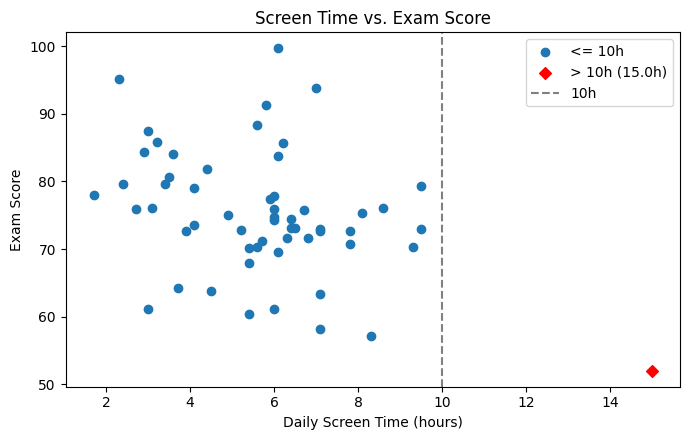

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", 20)

# 1. 建立可重跑的模擬資料（保留 df）
np.random.seed(42)
n = 60

df = pd.DataFrame({
    "student_id": [f"S{i:03d}" for i in range(1, n + 1)],
    "department": np.random.choice(
        ["資工系", "企管系", "外文系"], size=n, p=[0.4, 0.35, 0.25]
    ),
    "study_hours": np.round(np.random.normal(14.0, 4.0, n).clip(2, 28), 1),
    "screen_time": np.round(np.random.normal(5.5, 2.0, n).clip(1, 9.5), 1),
})
df["exam_score"] = np.round(
    (
        65
        + 1.4 * df["study_hours"]
        - 1.8 * df["screen_time"]
        + np.random.normal(0, 6, n)
    ).clip(40, 100),
    1,
)

# 注入缺失值與 15 小時極端紀錄
df.loc[[3, 17, 41], "study_hours"] = np.nan
df.loc[[10, 17, 52], "exam_score"] = np.nan
df.loc[59, ["department", "study_hours", "screen_time", "exam_score"]] = [
    "資工系",
    12.0,
    15.0,
    52.0,
]

# 2. 科系分組筆數與平均
dept_summary = (
    df.groupby("department")
    .agg(
        總筆數=("student_id", "count"),
        讀書有效數=("study_hours", "count"),
        平均讀書時數=("study_hours", "mean"),
        平均螢幕時間=("screen_time", "mean"),
        成績有效數=("exam_score", "count"),
        平均成績=("exam_score", "mean"),
    )
    .round(2)
)
print(dept_summary)

# 3. 有效配對相關分析：比較保留 vs 排除 screen_time > 10
for name, sub in [
    ("保留全部", df),
    ("排除 >10h", df[df["screen_time"] <= 10]),
]:
  p_study = sub[["study_hours", "exam_score"]].dropna()
  p_screen = sub[["screen_time", "exam_score"]].dropna()
  print(
      f"[{name}] 讀書配對 n={len(p_study)},"
      f" r={p_study['study_hours'].corr(p_study['exam_score']):.4f} | 螢幕配對"
      f" n={len(p_screen)},"
      f" r={p_screen['screen_time'].corr(p_screen['exam_score']):.4f}"
  )

# 4. 散佈圖
valid = df[["screen_time", "exam_score"]].dropna()
plt.figure(figsize=(7, 4.5))
plt.scatter(
    valid[valid["screen_time"] <= 10]["screen_time"],
    valid[valid["screen_time"] <= 10]["exam_score"],
    label="<= 10h",
)
plt.scatter(
    valid[valid["screen_time"] > 10]["screen_time"],
    valid[valid["screen_time"] > 10]["exam_score"],
    color="red",
    marker="D",
    label="> 10h (15.0h)",
)
plt.axvline(10, color="gray", linestyle="--", label="10h")
plt.xlabel("Daily Screen Time (hours)")
plt.ylabel("Exam Score")
plt.title("Screen Time vs. Exam Score")
plt.legend()
plt.tight_layout()
plt.show()


### ✍️ 小任務 MB｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：探討學生的每日讀書時數、每日螢幕時間與期末成績的關聯性，並比較保留與排除screen_time>10（含15小時）的結果差異。使用以隨機種子42生成的60筆模擬學生資料框df，包含欄位student_id、department、study_hours、screen_time、exam_score
- 實際輸出與至少一項依據數字的觀察：企管系18筆（平均讀書14.05小時、螢幕5.67小時、成績77.51分）、外文系14筆（12.54小時、5.59小時、72.17分）、資工系28筆（13.95小時、5.89小時、74.88分）。保留全資料時，讀書與成績呈中度正相關、螢幕與成績呈中低度負相關；排除screen_time>10後，讀書正相關微升，螢幕負相關則明顯變弱
- 圖表或模型結果的解讀（依任務要求）：plt.scatter 散佈圖顯示 15.0 小時極端點偏右且低分，會把整體趨勢線往下拉
- 資料品質、模擬資料或評估限制：為線性公式合成模擬資料，非真實校務資料、無因果推論；已核對各組人數加總為 60 且 dropna() 配對數一致。
- 驗證方法與結果：檢查任務要求與輸出結果相符
- AI 工具、實際提示詞、人工修改與遇到的問題：Gemini Flash-Lite。我是 Python 初學者，請協助我完成以下資料分析小任務：
請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果以「學習行為與成績」為問題，至少完成一次科系的分組筆數與平均、一次含有效配對數的相關分析，以及一張圖；比較保留／排除螢幕時間大於 10 的結果。 <BR>*產出規劃、程式與報告時遇到中文字寬度造成表格沒對齊，加上 pd.set_option('display.unicode.east_asian_width', True) 改善了一點
- 重新執行是否成功及環境或檔案需求：執行環境需具備 Python 3 與 numpy、pandas、matplotlib 套件，因全程使用固定隨機種子生成模擬資料，不依賴外部輸入檔案，可在相同套件環境下完整重現數值與圖表
